In [2]:
library(dplyr)
library(ggplot2)


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




In [3]:
# Generate synthetic data on Marketing vs. Sales
XLABEL <- "Marketing investment ($)"
YLABEL <- "Revenue (1000$)"
SAMPLES <- 100

x <- seq(SAMPLES)

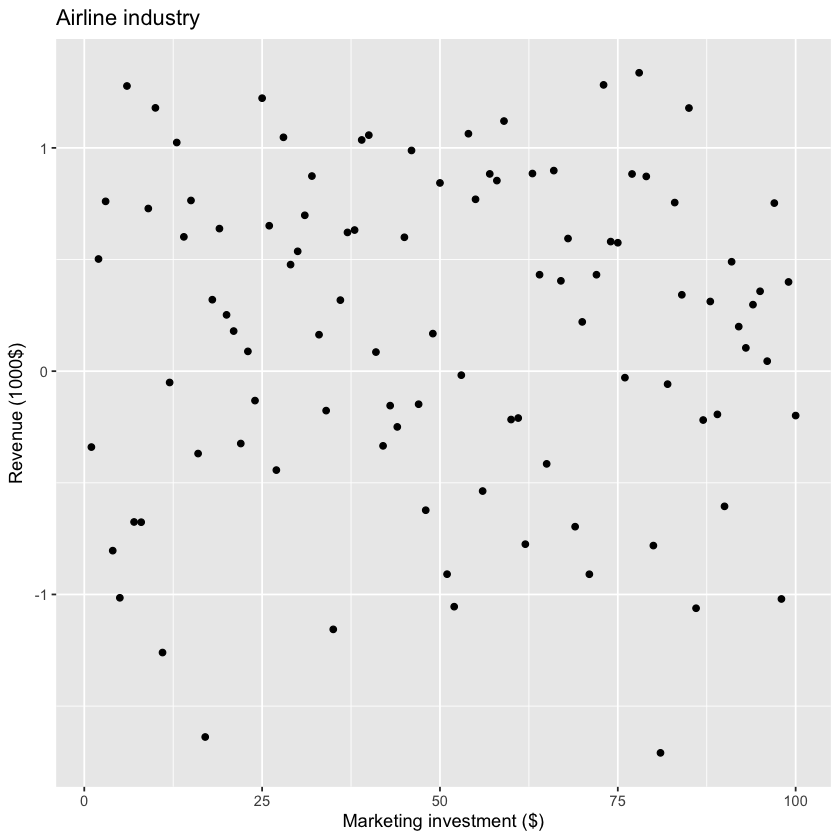

`geom_smooth()` using formula = 'y ~ x'


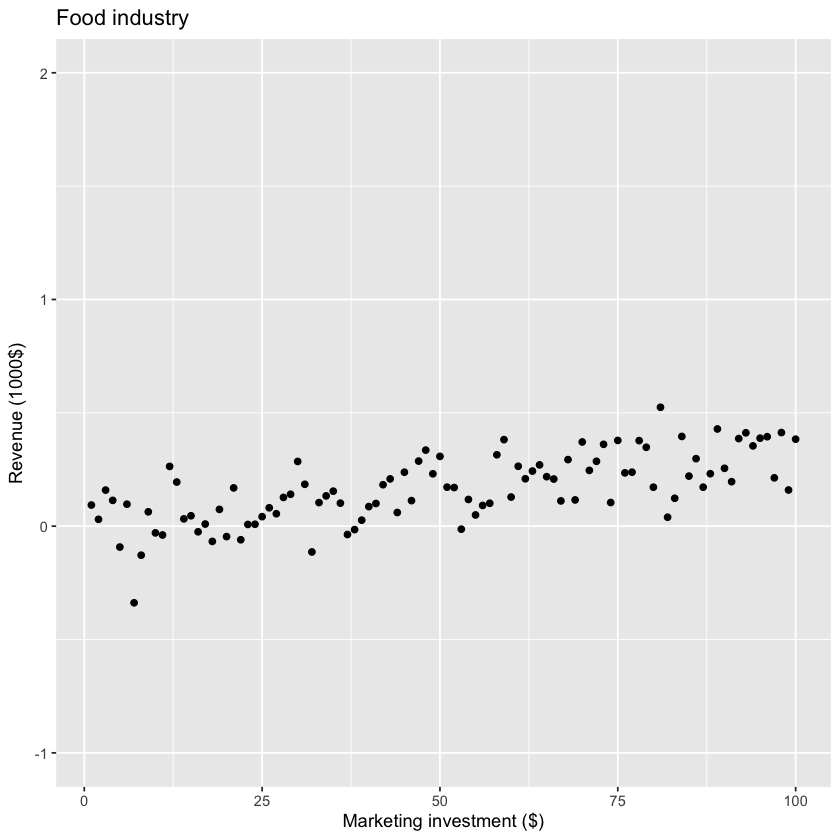

`geom_smooth()` using formula = 'y ~ x'


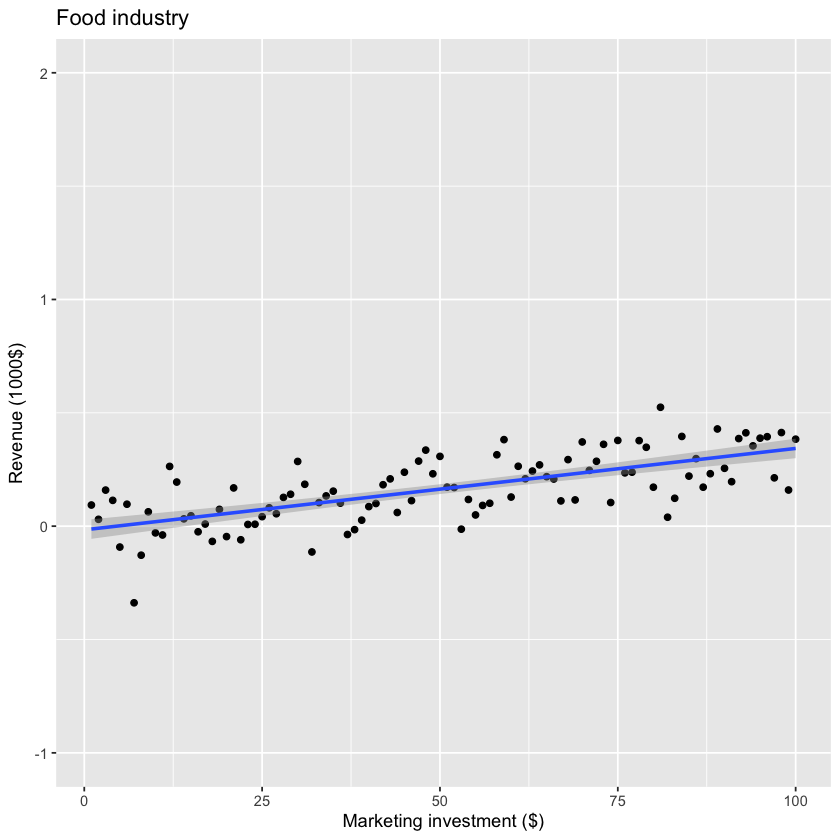

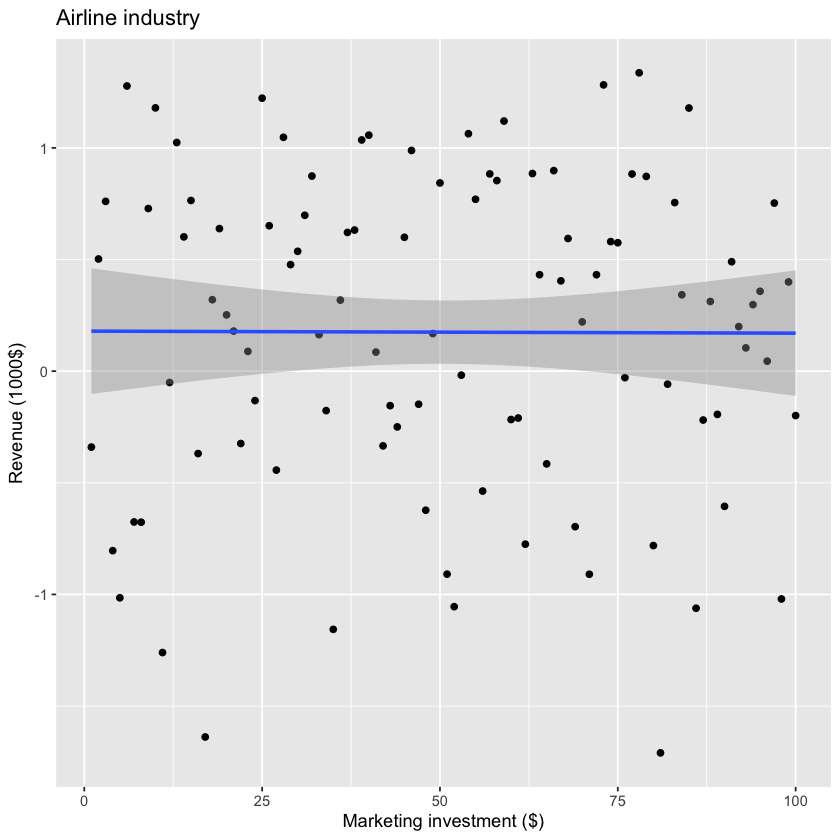

In [4]:
#-------------------------------------------------------------------------------
# Compare 2 industries. Generate the dependent variable Y 
y_airlines_industry <- 0.003*x + rnorm(SAMPLES, sd = 0.8)
y_food_industry <- 0.003*x + rnorm(SAMPLES, sd = 0.12)

df_air <- data.frame(x = x,
                     y = y_airlines_industry)

df_food <- data.frame(x = x,
                      y = y_food_industry)

# Plot the Airlines industry
p1 <- df_air %>%
  ggplot(aes(x=x, y=y)) +
  geom_point() +
  xlab(XLABEL) + ylab(YLABEL) + ggtitle("Airline industry")
p1

# Plot the Food industry
p2 <- df_food %>%
  ggplot(aes(x=x, y=y)) +
  geom_point() +
  ylim(-1, 2) +
  xlab(XLABEL) + ylab(YLABEL) + ggtitle("Food industry")
p2

# Add a regression line to both graphs. Note how easy it is with ggplot
p2 + geom_smooth(method='lm')
p1 + geom_smooth(method='lm')


# Why do you "trust" the food industry regression more?
# Run the script a few times and observe the regression for the Airline industry. Does it change?
#     Does Food industry regression change?
#-------------------------------------------------------------------------------

# What you observed stem from the fact that the regression coefficients are calculated from the data.
# The data are just a sample of larger population and are inherently random. As a result, also 
# Beta coefficients are random. The more X varies the more also Beta varies (the grey region indicates
# where the Betas can be expected with various samples)

# The null hypothesis we test using this distribution of Betas is H0: "The true Beta coefficient is 0"
# I.e. if there is a reasonable chance the regression can be a horizontal line, we cannot reject the null. 
# The implication for our model is that the Beta (and the associated feature) is not important for our model